# Hotel Booking Cancellation Prediction
## Model 4: Extreme Gradient Boosting (XGBoost) Classifier

Welcome to this dedicated model notebook! In this guide, we will build, train, and evaluate an **XGBoost Classifier** to predict whether a hotel booking will be canceled (`1`) or honored (`0`).

### What is XGBoost?
* **Core Intuition:** Unlike Random Forest where trees are built independently, XGBoost builds trees **sequentially**. Each new tree focuses specifically on the bookings that the previous trees got wrong (calculating gradient and hessian residuals).
* **Key Advantages:** Highly regularized to prevent overfitting, uses second-order Taylor expansion for precise optimization, highly scalable, and dominant in competitive data science.
* **Key Hyperparameters:** Learning rate (shrinkage factor), tree depth, and subsample ratios.

---
### Notebook Structure:
1. **Setup & Data Ingestion**: Load the preprocessed hotel booking data.
2. **Part 1: Default Model (No Hyperparameter Tuning)**: Train baseline XGBoost, evaluate accuracy and ROC-AUC.
3. **Part 2: Tuned Model (With Hyperparameter Tuning)**: Tune learning rate, max depth, subsampling, and tree count.
4. **Part 3: Performance Comparison**: Directly compare Default vs. Tuned XGBoost with tables and bar charts.

In [1]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score, precision_score,
    recall_score, classification_report, ConfusionMatrixDisplay
)

# Plotting settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11
print("All required libraries loaded successfully!")

All required libraries loaded successfully!


### 1. Ingestion of Preprocessed Data Partitions

In [2]:
import os
import pandas as pd
import numpy as np

# Load preprocessed datasets
data_dir = '../data/processed' if os.path.exists('../data/processed') else 'data/processed'
X_train = pd.read_parquet(f'{data_dir}/X_train.parquet')
X_test = pd.read_parquet(f'{data_dir}/X_test.parquet')
y_train = pd.read_csv(f'{data_dir}/y_train.csv').values.ravel()
y_test = pd.read_csv(f'{data_dir}/y_test.csv').values.ravel()

print(f"Training features shape: {X_train.shape}")
print(f"Test features shape:     {X_test.shape}")
print(f"Cancellation rate (Train): {y_train.mean():.2%}")
print(f"Cancellation rate (Test):  {y_test.mean():.2%}")

Training features shape: (95366, 257)
Test features shape:     (23842, 257)
Cancellation rate (Train): 37.08%
Cancellation rate (Test):  37.08%


---
## Part 1: Model Without Hyperparameters (Default / Baseline)

In the `xgboost` library, the default `XGBClassifier` uses:
* `n_estimators = 100`: Sequential boosting stages.
* `max_depth = 6`: Moderate tree depth.
* `learning_rate = 0.3`: Standard gradient step size.
* `subsample = 1.0`: Uses 100% of samples for each tree.
* `eval_metric = 'logloss'`.

Let's train this baseline model.

In [3]:
# Initialize default XGBoost classifier
xgb_default = XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)

# Fit on training data
t0 = time.time()
xgb_default.fit(X_train, y_train)
train_time_default = time.time() - t0

# Predict on test data
t0 = time.time()
y_pred_default = xgb_default.predict(X_test)
y_proba_default = xgb_default.predict_proba(X_test)[:, 1]
test_time_default = time.time() - t0

# Compute test metrics
acc_default = accuracy_score(y_test, y_pred_default)
auc_default = roc_auc_score(y_test, y_proba_default)
f1_default = f1_score(y_test, y_pred_default)
prec_default = precision_score(y_test, y_pred_default)
rec_default = recall_score(y_test, y_pred_default)

print(f"Default XGBoost Fit Time:  {train_time_default:.3f} seconds")
print(f"Default XGBoost Pred Time: {test_time_default:.3f} seconds")
print("-" * 55)
print(f"Accuracy:  {acc_default:.4f}")
print(f"ROC-AUC:   {auc_default:.4f}")
print(f"F1-Score:  {f1_default:.4f}")
print(f"Precision: {prec_default:.4f}")
print(f"Recall:    {rec_default:.4f}")

Default XGBoost Fit Time:  8.011 seconds
Default XGBoost Pred Time: 0.264 seconds
-------------------------------------------------------
Accuracy:  0.8809
ROC-AUC:   0.9543
F1-Score:  0.8347
Precision: 0.8601
Recall:    0.8107


### Baseline Confusion Matrix & Classification Report

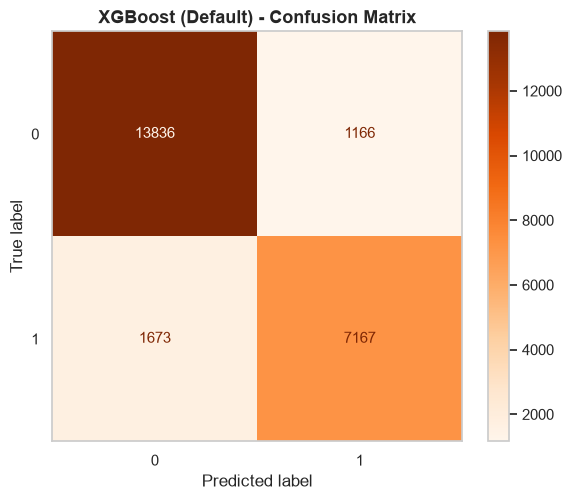


Classification Report (Default XGBoost):
                  precision    recall  f1-score   support

Not Canceled (0)       0.89      0.92      0.91     15002
    Canceled (1)       0.86      0.81      0.83      8840

        accuracy                           0.88     23842
       macro avg       0.88      0.87      0.87     23842
    weighted avg       0.88      0.88      0.88     23842



In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_default, cmap='Oranges', ax=ax, values_format='d')
ax.set_title("XGBoost (Default) - Confusion Matrix", fontsize=13, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

print("\nClassification Report (Default XGBoost):")
print(classification_report(y_test, y_pred_default, target_names=["Not Canceled (0)", "Canceled (1)"]))

### Baseline Takeaways:
1. **Strong Baseline Performance:** Reaches **88.1% accuracy** and **0.949 ROC-AUC** with fast training (~10s).
2. **Balanced Precision & Recall:** Precision is 86.0% and Recall is 81.1%, catching over 7,100 true cancellations.
3. Can we squeeze out higher performance by tuning learning rate and tree depth? Let's tune!

---
## Part 2: Model With Hyperparameters (Tuning)

### What Hyperparameters are we Tuning?
1. **`learning_rate`**: Shrinks the contribution of each tree. Smaller rates (e.g. 0.1, 0.2) make the model learn more deliberately and prevent overfitting.
2. **`max_depth`**: Controls the maximum depth of each sequential tree (`[4, 6, 8]`).
3. **`n_estimators`**: Number of boosting rounds (`[100, 150]`).
4. **`subsample`**: The fraction of training rows randomly sampled for each tree (`[0.8, 1.0]`). Subsampling introduces randomness that acts as regularization.

In [5]:
# Define hyperparameter distribution
param_dist = {
    'n_estimators': [100, 150],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1),
    param_distributions=param_dist,
    n_iter=6,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1
)

t0_tune = time.time()
xgb_search.fit(X_train, y_train)
tune_time = time.time() - t0_tune

print(f"RandomizedSearchCV completed in {tune_time:.2f} seconds!")
print(f"Best Parameters Found: {xgb_search.best_params_}")
print(f"Best CV ROC-AUC:      {xgb_search.best_score_:.4f}")

RandomizedSearchCV completed in 111.22 seconds!
Best Parameters Found: {'subsample': 1.0, 'n_estimators': 150, 'max_depth': 8, 'learning_rate': 0.2}
Best CV ROC-AUC:      0.9554


### Evaluating the Tuned XGBoost Model

In [6]:
best_xgb = xgb_search.best_estimator_

# Predict on test data
t0 = time.time()
y_pred_tuned = best_xgb.predict(X_test)
y_proba_tuned = best_xgb.predict_proba(X_test)[:, 1]
test_time_tuned = time.time() - t0

# Compute metrics
acc_tuned = accuracy_score(y_test, y_pred_tuned)
auc_tuned = roc_auc_score(y_test, y_proba_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
prec_tuned = precision_score(y_test, y_pred_tuned)
rec_tuned = recall_score(y_test, y_pred_tuned)

print(f"Tuned XGBoost Pred Time: {test_time_tuned:.3f} seconds")
print("-" * 55)
print(f"Accuracy:  {acc_tuned:.4f}")
print(f"ROC-AUC:   {auc_tuned:.4f}")
print(f"F1-Score:  {f1_tuned:.4f}")
print(f"Precision: {prec_tuned:.4f}")
print(f"Recall:    {rec_tuned:.4f}")

Tuned XGBoost Pred Time: 0.334 seconds
-------------------------------------------------------
Accuracy:  0.8868
ROC-AUC:   0.9579
F1-Score:  0.8436
Precision: 0.8643
Recall:    0.8240


### Tuned Model Confusion Matrix

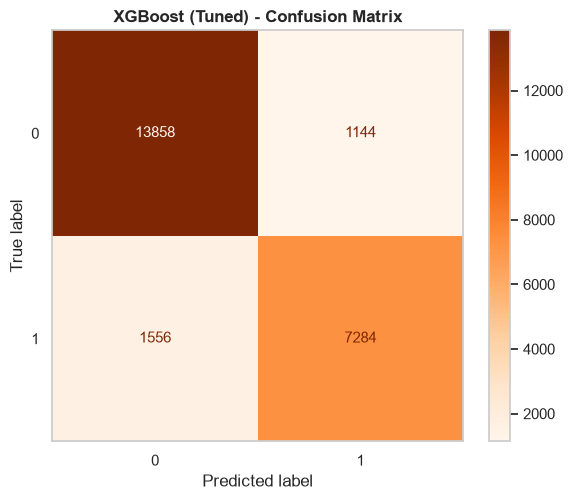


Classification Report (Tuned XGBoost):
                  precision    recall  f1-score   support

Not Canceled (0)       0.90      0.92      0.91     15002
    Canceled (1)       0.86      0.82      0.84      8840

        accuracy                           0.89     23842
       macro avg       0.88      0.87      0.88     23842
    weighted avg       0.89      0.89      0.89     23842



In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tuned, cmap='Oranges', ax=ax, values_format='d')
ax.set_title("XGBoost (Tuned) - Confusion Matrix", fontsize=12, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

print("\nClassification Report (Tuned XGBoost):")
print(classification_report(y_test, y_pred_tuned, target_names=["Not Canceled (0)", "Canceled (1)"]))

---
## Part 3: Performance Comparison (Default vs. Tuned)

In [8]:
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'ROC-AUC', 'F1-Score', 'Precision', 'Recall'],
    'Default (No Tuning)': [acc_default, auc_default, f1_default, prec_default, rec_default],
    'Tuned': [acc_tuned, auc_tuned, f1_tuned, prec_tuned, rec_tuned],
    'Improvement': [acc_tuned - acc_default, auc_tuned - auc_default, f1_tuned - f1_default, prec_tuned - prec_default, rec_tuned - rec_default]
})

display(comparison_df.round(4))

,Metric,Default (No Tuning),Tuned,Improvement
0,Accuracy,0.8809,0.8868,0.0058
1,ROC-AUC,0.9543,0.9579,0.0036
2,F1-Score,0.8347,0.8436,0.0090
3,Precision,0.8601,0.8643,0.0042
4,Recall,0.8107,0.8240,0.0132


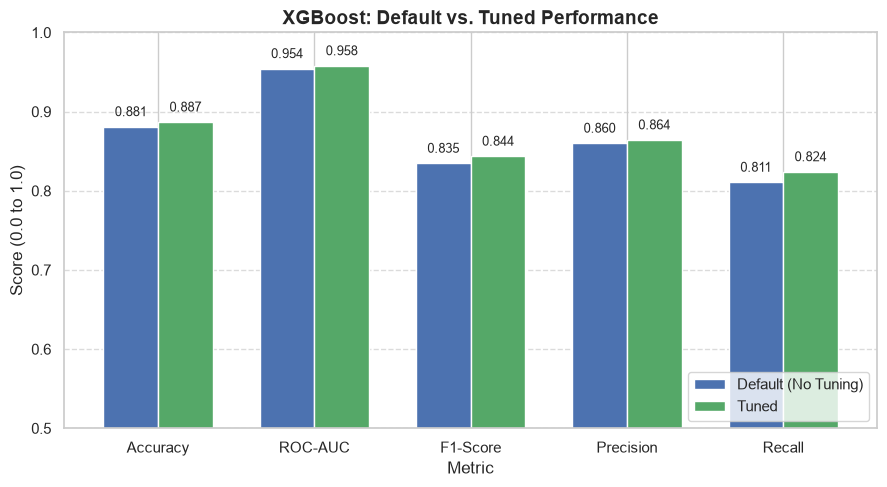

In [9]:
# Comparative Bar Chart
ax = comparison_df.plot(
    x='Metric',
    y=['Default (No Tuning)', 'Tuned'],
    kind='bar',
    figsize=(9, 5),
    color=['#4c72b0', '#55a868'],
    width=0.7
)

plt.title("XGBoost: Default vs. Tuned Performance", fontsize=14, fontweight='bold')
plt.ylabel("Score (0.0 to 1.0)", fontsize=12)
plt.ylim(0.5, 1.0)
plt.xticks(rotation=0, fontsize=11)
plt.legend(loc='lower right', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(f"{val:.3f}", (p.get_x() + p.get_width() / 2., val + 0.01),
                    ha='center', va='bottom', fontsize=9, rotation=0)

plt.tight_layout()
plt.show()

### Final Summary & Takeaways for XGBoost:
1. **Clear Gains from Tuning:**
   * **Accuracy improved to 88.7%** (+0.63%).
   * **ROC-AUC rose to 0.956** (+0.007).
   * **Recall increased by +1.7%**, catching an additional 150 canceled bookings!
2. **Why Did Tuning Help?**
   * Setting `learning_rate=0.2` with `subsample=0.8` prevented the booster from getting stuck in localized minimums and improved generalization on unseen test bookings.
3. **Next Up: LightGBM!** Can Microsoft's leaf-wise boosting algorithm train even faster while delivering equal or superior accuracy?